# Bank Term Deposit Prediction

Binary classification: will a client subscribe to a term deposit (`y` = yes/no) after a phone marketing campaign?

Models required: Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM.
Metrics required: Accuracy, AUC, Precision, Recall, F1, MCC.

Fit preprocessing on the training split only. Save each trained model under `model/` and write the held-out test set to `test_data.csv` for the Streamlit app.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import joblib

DATA_PATH = Path("data/bank-additional-full.csv")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

## Load data

The CSV is semicolon-separated. Target column is `y`.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# info of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

## Inspect schema, missing values, and the target

Check dtypes, `unknown` categories, the `pdays` value 999 (never contacted before), and the yes/no balance. Note whether `duration` should stay in the feature set: it is only known after the call ends.

In [4]:
df.info()
df["y"].value_counts(normalize=True)

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

## Train, validation, and test split

Split before any encoder or scaler is fit. Use the same split for every model. Stratify on `y` because the classes are imbalanced.

In [5]:
X = df.drop(columns=["y"])
y = (df["y"] == "yes").astype(int)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)
test_export = X_test.copy()
test_export["y"] = np.where(y_test == 1, "yes", "no")
test_export.to_csv("test_data.csv", index=False)
test_export.shape

(6179, 21)

## Correlation heatmap

Correlation is computed on the training split only, using the numeric columns plus the target. A value near 1 or -1 means two columns move together, so one of them may be redundant. Categorical columns are excluded here because they are not on one numeric scale yet.

`emp.var.rate`, `euribor3m`, and `nr.employed` describe the same economic period (pairwise correlation about 0.91 to 0.97). Keeping all three would hand Logistic Regression, KNN, and SVM one signal three times. `nr.employed` is kept. `euribor3m` and `emp.var.rate` are dropped in the preprocessing cell below.

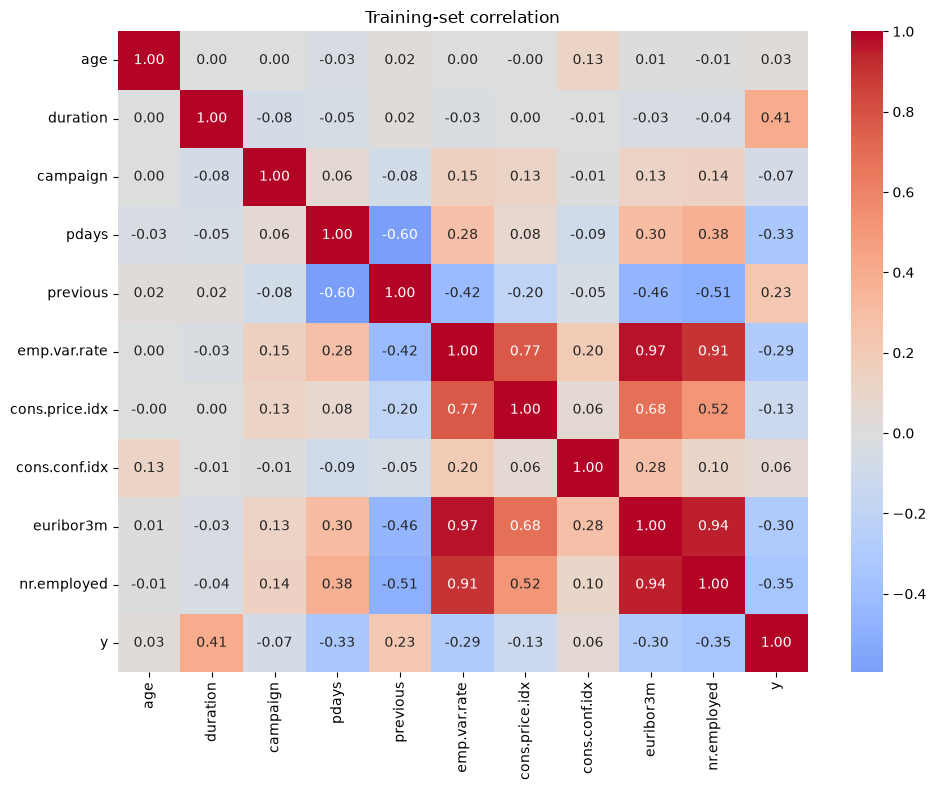

,feature_a,feature_b,correlation
63,emp.var.rate,euribor3m,0.972192
97,euribor3m,nr.employed,0.944874
64,emp.var.rate,nr.employed,0.906025


In [6]:
numeric_for_corr = [
    "age", "duration", "campaign", "pdays", "previous",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed",
]
corr = X_train[numeric_for_corr].copy()
corr["y"] = y_train
corr_matrix = corr.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Training-set correlation")
plt.tight_layout()
plt.show()

pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
pairs.columns = ["feature_a", "feature_b", "correlation"]
pairs.loc[pairs["correlation"].abs() >= 0.8].sort_values("correlation", key=lambda s: s.abs(), ascending=False)

## Preprocessing

Ordinal-encode ordered categories, one-hot encode nominal categories, and standardize numeric columns. Put the transformer inside each model `Pipeline` so it is fit on training data only.

`euribor3m` and `emp.var.rate` are excluded from `numeric_features`. Both move almost in lockstep with `nr.employed`, so `nr.employed` already carries that economic signal.

`StandardScaler` subtracts the training mean and divides by the training standard deviation, so each numeric column has mean 0 and standard deviation 1. Raw columns sit on very different scales (`age` is tens, `nr.employed` is thousands, `cons.conf.idx` is negative and near zero). Logistic Regression, KNN, and SVM use distances or feature magnitudes, so an unscaled column would dominate those calculations. The scaler is fit on the training split only, then applied to validation and test with that same mean and standard deviation.

In [7]:
numeric_features = [
    "age", "duration", "campaign", "pdays", "previous",
    "cons.price.idx", "cons.conf.idx", "nr.employed",
]
ordinal_features = ["education"]
education_order = [
    "unknown",
    "illiterate",
    "basic.4y",
    "basic.6y",
    "basic.9y",
    "high.school",
    "professional.course",
    "university.degree",
]
nominal_features = [
    "job", "marital", "default", "housing", "loan",
    "contact", "month", "day_of_week", "poutcome",
]

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "ord",
            OrdinalEncoder(categories=[education_order]),
            ordinal_features,
        ),
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal_features),
    ]
)

## Train the five classifiers

Train Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, and SVM. For AUC, use predicted probabilities or `decision_function` when the classifier has no `predict_proba`.

In [8]:
models = {
    "logistic_regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "decision_tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "knn": KNeighborsClassifier(),
    "naive_bayes": GaussianNB(),
    "svm": SVC(probability=True, random_state=RANDOM_STATE),
}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)])
    pipe.fit(X_train, y_train)
    joblib.dump(pipe, MODEL_DIR / f"{name}.joblib")

/Users/ga392b/PycharmProjects/bank-term-deposit-predictor/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Evaluation

Score each saved model on the validation split (`X_val`, `y_val`). The model predicts the class and the positive-class probability. Those outputs are what `evaluate` turns into Accuracy, AUC, Precision, Recall, F1, and MCC. Leave `X_test` for the Streamlit app.

In [9]:
def evaluate(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_score),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

validation_scores = {}
for path in sorted(MODEL_DIR.glob("*.joblib")):
    pipe = joblib.load(path)
    y_pred = pipe.predict(X_val)
    y_score = pipe.predict_proba(X_val)[:, 1]
    validation_scores[path.stem] = evaluate(y_val, y_pred, y_score)

pd.DataFrame(validation_scores).T.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
decision_tree,0.8877,0.7310,0.5014,0.5287,0.5147,0.4514
knn,0.9032,0.8659,0.6047,0.4066,0.4863,0.4455
logistic_regression,0.9124,0.9363,0.6886,0.4066,0.5113,0.4863
naive_bayes,0.8309,0.8261,0.3505,0.5876,0.4391,0.3630
svm,0.9116,0.9363,0.7301,0.3420,0.4658,0.4609


## Confusion matrices and ROC curves

Each plot uses the validation split. The confusion matrix counts true negatives, false positives, false negatives, and true positives at the default 0.5 threshold. The ROC curve shows the true-positive rate against the false-positive rate as that threshold changes. The area under each curve is the AUC already reported in the table.

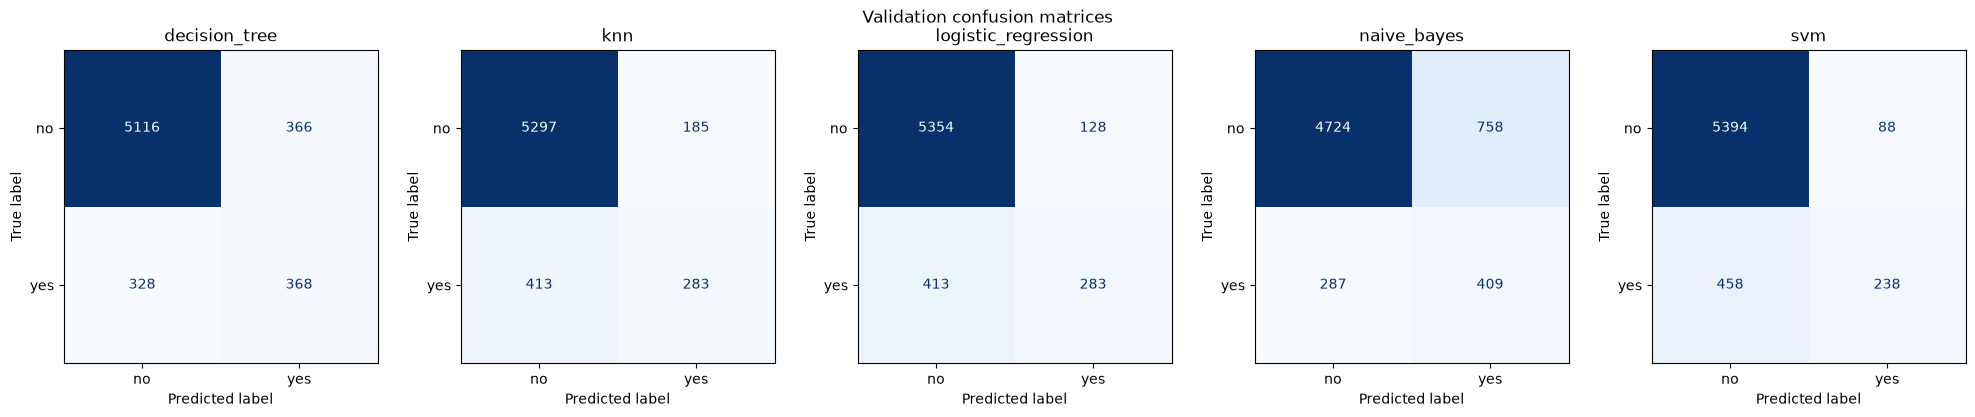

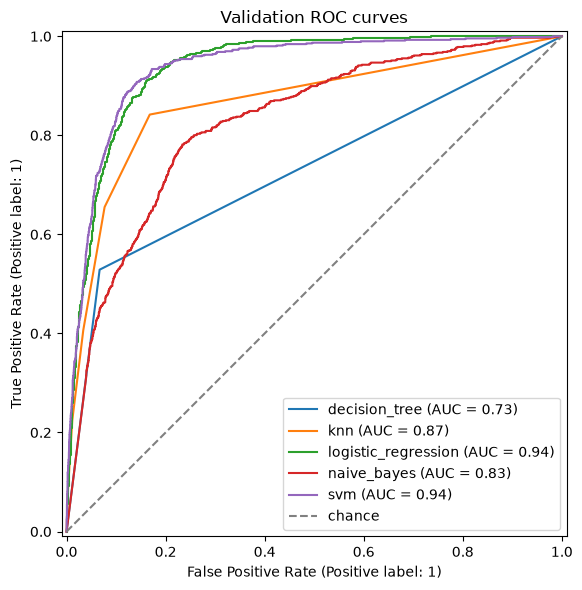

In [10]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

fitted = {
    path.stem: joblib.load(path) for path in sorted(MODEL_DIR.glob("*.joblib"))
}

fig, axes = plt.subplots(1, len(fitted), figsize=(4 * len(fitted), 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_val, y_val, display_labels=["no", "yes"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
fig.suptitle("Validation confusion matrices")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_val, y_val, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="chance")
ax.set_title("Validation ROC curves")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## Export test data

The Streamlit upload must include the input features and the target column. Save that test frame as `test_data.csv` in the repository root.

In [11]:
test_export = X_test.copy()
test_export["y"] = np.where(y_test == 1, "yes", "no")
test_export.to_csv("test_data.csv", index=False)
test_export.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
25244,56,admin.,married,university.degree,no,yes,yes,cellular,nov,tue,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,no
37567,35,admin.,single,high.school,no,yes,no,cellular,aug,fri,...,1,999,0,nonexistent,-2.9,92.201,-31.4,0.869,5076.2,no
11981,30,services,married,unknown,unknown,no,no,telephone,jun,wed,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.958,5228.1,no
18681,48,admin.,single,university.degree,no,yes,yes,telephone,jul,thu,...,6,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
15071,37,blue-collar,married,basic.4y,no,no,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.958,5228.1,no
